# Pascal VOC 2012: Data Exploration

Inspect object-detection annotations, summarize all 20 categories, and save reproducible training and development-validation splits. This notebook does not train a model.

**Run from top to bottom** using the project’s `Pascal VOC (.venv)` kernel. The notebook assumes its working directory is the repository root and that `VOCdevkit` is a sibling of the repository.

## Evaluation plan

| Role | Images | Source |
|---|---:|---|
| Training | 4,573 | 80% of official detection `train` |
| Development validation | 1,144 | 20% of official detection `train` |
| Final held-out evaluation | 5,823 | Official detection `val`, left untouched here |

The separately downloaded official test images are not used in this approach.


In [ ]:
from pathlib import Path
import sys

project_dir = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / "voc_detection").is_dir() and (path / "configs").is_dir()
)
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))


## 1. Read the official training split

Load image IDs from `ImageSets/Main/train.txt`. An ID connects a photo to its XML annotation; reading this list does not load the photos.


In [25]:
from pathlib import Path

dataset_dir = (project_dir.parent / "VOCdevkit" / "VOC2012").resolve()

train_split = dataset_dir / "ImageSets/Main/train.txt"
train_ids = train_split.read_text().splitlines()

print("Training images:", len(train_ids))
print("First five IDs:", train_ids[:5])


Training images: 5717
First five IDs: ['2008_000008', '2008_000015', '2008_000019', '2008_000023', '2008_000028']


## 2. Connect one image to its annotation

Use an ID to open a JPG photograph and its matching XML file. Extract every object’s category, bounding box, and difficult flag. These are ground-truth labels, not predictions. Only official training images are inspected.


In [26]:
import xml.etree.ElementTree as ET

from PIL import Image

image_id = train_ids[1500]
image_path = dataset_dir / "JPEGImages" / f"{image_id}.jpg"
annotation_path = dataset_dir / "Annotations" / f"{image_id}.xml"

image = Image.open(image_path).convert("RGB")
annotation = ET.parse(annotation_path).getroot()

objects = []
for obj in annotation.findall("object"):
    box = obj.find("bndbox")
    objects.append(
        {
            "name": obj.findtext("name"),
            "xmin": int(box.findtext("xmin")),
            "ymin": int(box.findtext("ymin")),
            "xmax": int(box.findtext("xmax")),
            "ymax": int(box.findtext("ymax")),
            "difficult": int(obj.findtext("difficult", "0")),
        }
    )

print("Image ID:", image_id)
print("Image size (width, height):", image.size)
print("Number of labeled objects:", len(objects))
for obj in objects:
    print(obj)


Image ID: 2008_006329
Image size (width, height): (375, 500)
Number of labeled objects: 2
{'name': 'cat', 'xmin': 57, 'ymin': 47, 'xmax': 182, 'ymax': 336, 'difficult': 0}
{'name': 'cat', 'xmin': 112, 'ymin': 99, 'xmax': 318, 'ymax': 498, 'difficult': 0}


## 3. Visualize the ground-truth boxes

VOC coordinates start at 1 and include both endpoints. For display, subtract 1 from the left/top coordinates and include the final pixel in the width and height. Dashed boxes indicate objects marked `difficult`.


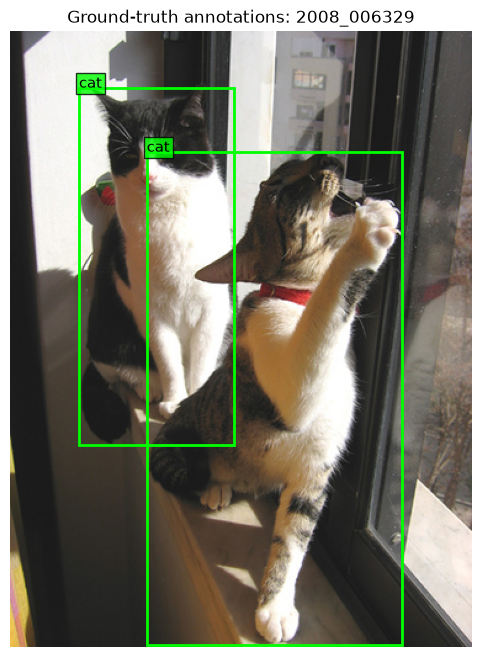

In [27]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(image, extent=(0, image.width, image.height, 0))

for obj in objects:
    x = obj["xmin"] - 1
    y = obj["ymin"] - 1
    width = obj["xmax"] - obj["xmin"] + 1
    height = obj["ymax"] - obj["ymin"] + 1

    rectangle = Rectangle(
        (x, y),
        width,
        height,
        fill=False,
        edgecolor="lime",
        linewidth=2,
        linestyle="--" if obj["difficult"] else "-",
    )
    ax.add_patch(rectangle)
    label = obj["name"] + (" (difficult)" if obj["difficult"] else "")
    ax.text(
        x,
        y,
        label,
        color="black",
        fontsize=11,
        bbox={"facecolor": "lime", "alpha": 0.8, "pad": 2},
    )

ax.set_title(f"Ground-truth annotations: {image_id}")
ax.axis("off")
plt.show()


### Visual inspection

Check that each label matches its object and that the box surrounds the annotated visible extent. Notice small, overlapping, occluded, or truncated objects.

To view another example, change the index in `image_id = train_ids[1500]` in section 2, then rerun sections 2 and 3.


## 4. Explore category distributions

Build one table row per annotated object in the official training split. `images` counts distinct photos; `objects` includes difficult instances; `difficult_objects` counts that subset.


In [28]:
import pandas as pd

rows = []

for image_id in train_ids:
    annotation_path = dataset_dir / "Annotations" / f"{image_id}.xml"
    annotation = ET.parse(annotation_path).getroot()

    for obj in annotation.findall("object"):
        rows.append(
            {
                "image_id": image_id,
                "category": obj.findtext("name"),
                "difficult": int(obj.findtext("difficult", "0")),
            }
        )

objects_df = pd.DataFrame(rows)

summary = (
    objects_df.groupby("category")
    .agg(
        images=("image_id", "nunique"),
        objects=("image_id", "size"),
        difficult_objects=("difficult", "sum"),
    )
    .sort_values("objects", ascending=False)
)

summary


,images,objects,difficult_objects
category,,,
person,2142,5019,825
chair,656,1457,279
car,621,1191,178
dog,636,768,12
bottle,399,749,120
cat,540,609,4
bird,399,592,32
pottedplant,289,557,73
sheep,171,509,109


### Plot non-difficult and difficult instances


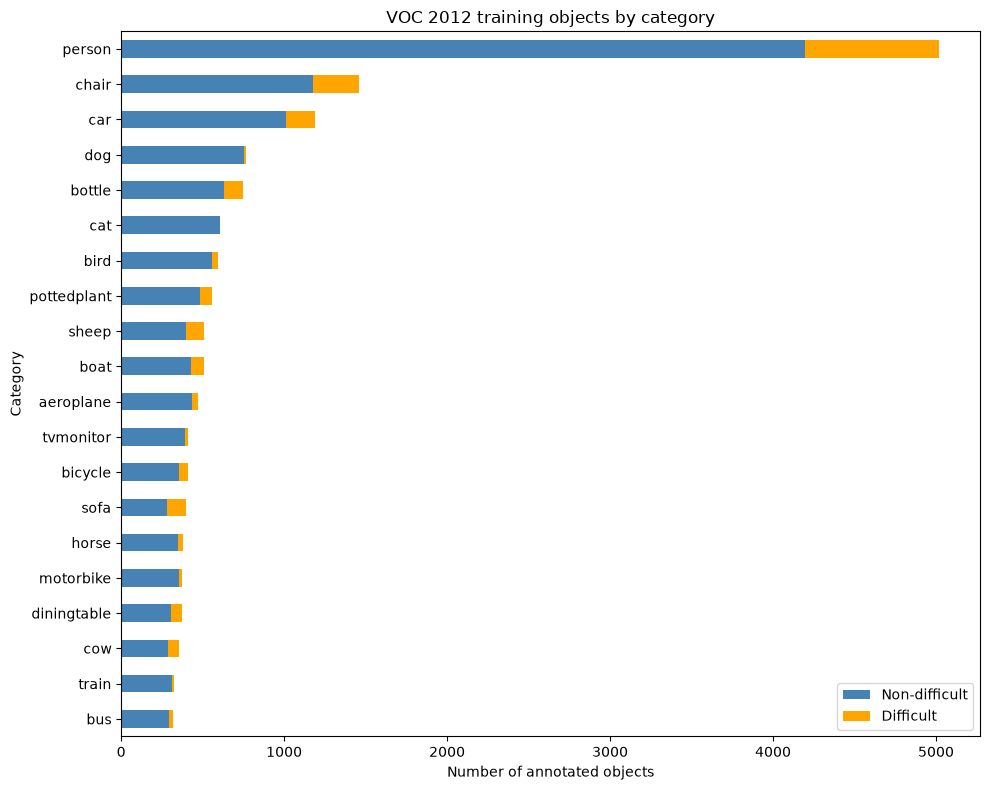

In [29]:
plot_data = pd.DataFrame(
    {
        "Non-difficult": summary["objects"] - summary["difficult_objects"],
        "Difficult": summary["difficult_objects"],
    }
)

ax = plot_data.plot.barh(
    stacked=True,
    figsize=(10, 8),
    color=["steelblue", "orange"],
)

ax.invert_yaxis()
ax.set_xlabel("Number of annotated objects")
ax.set_ylabel("Category")
ax.set_title("VOC 2012 training objects by category")

plt.tight_layout()
plt.show()


The training set is imbalanced: person annotations substantially outnumber other categories. Difficult-object proportions also vary by category. We will report per-class detection performance and preserve the difficult flags for evaluation.

## 5. Create a reproducible development split

Split whole images, keeping all objects in a photo together. `fit_ids` are used for model training; `dev_ids` are used to choose settings. The fixed seed makes this split repeatable. Assertions check disjointness and full coverage of the original training IDs.


In [30]:
from sklearn.model_selection import train_test_split

fit_ids, dev_ids = train_test_split(
    train_ids,
    test_size=0.20,
    random_state=42,
    shuffle=True,
)

print("Training:", len(fit_ids))
print("Development validation:", len(dev_ids))

assert set(fit_ids).isdisjoint(dev_ids)

assert set(fit_ids) | set(dev_ids) == set(train_ids)


Training: 4573
Development validation: 1144


## 6. Save the split manifests

Write the IDs to `splits/train.txt` and `splits/dev.txt` so every experiment uses the same examples. These small text files belong in version control. Rerunning this cell overwrites them with the same split when the inputs and seed are unchanged.


In [31]:
split_dir = project_dir / "splits"
split_dir.mkdir(exist_ok=True)

(split_dir / "train.txt").write_text("\n".join(sorted(fit_ids)) + "\n")

(split_dir / "dev.txt").write_text("\n".join(sorted(dev_ids)) + "\n")


13728

## 7. Check category coverage

Count non-difficult objects in each new split. Every category should have examples in both groups. This check does not remove difficult objects from the underlying annotations.


In [32]:
regular_objects = objects_df[objects_df["difficult"] == 0]

fit_counts = (
    regular_objects[regular_objects["image_id"].isin(fit_ids)]
    .groupby("category")
    .size()
)

dev_counts = (
    regular_objects[regular_objects["image_id"].isin(dev_ids)]
    .groupby("category")
    .size()
)

coverage = (
    pd.DataFrame(
        {
            "training_objects": fit_counts,
            "validation_objects": dev_counts,
        }
    )
    .reindex(summary.index)
    .fillna(0)
    .astype(int)
)

assert (coverage > 0).all().all(), "A category is missing from a split."

coverage


,training_objects,validation_objects
category,,
person,3299,895
chair,950,228
car,819,194
dog,609,147
bottle,496,133
cat,487,118
bird,453,107
pottedplant,363,121
sheep,328,72
